# 11. Head 분리 측정 (Phase A-5)

A-4-2에서 페어 1, 3 = 모델 한계 확정. 본 노트북은 cls head 약점 vs feature 부족을 분리.

## 가르려는 것
- **cls head 약점**: 박스(reg head)는 정확함 + cls head logit이 정답을 약하게 잡거나 1/2위 비슷
  → 처방: cls head 강화 (loss 가중, contrastive learning)
- **feature 부족**: 박스 정확 + cls head logit에서 정답이 매우 약함
  → 처방: backbone/neck 차원 (multi-scale, 더 큰 모델)
- **혼합**: 둘 다 작용

## 측정 방법
- 라벨 이동 케이스 (페어 1, 3 = 70건) 식별
- **reg head 측정**: GT bbox vs pred bbox IoU 분포
- **cls head 측정**: top1 vs top2 conf gap (확신 정도) + 정답 클래스가 top3 안에 있는지

## 데이터
- 세션 45에서 만든 K-code val 2090장 추론 결과 JSON 사용
- baseline (e15 best=e13) + v2 (e14 best=e14) 두 모델
- conf threshold 0.05로 컷, top3만 저장 → 정답이 top3 밖인 경우 "매우 낮음"만 측정 가능

## 한계
- cls head 전체 logit (118 클래스) 못 봄
- 필요 시 라벨 이동 케이스만 재추론 (logit 전체 저장)

In [2]:
import json
import unicodedata
import numpy as np
import pandas as pd
import cv2
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False

ROOT = Path(r'D:\pill_detection')
ANALYSIS_DIR = ROOT / 'analysis'
DATA_DIR = ANALYSIS_DIR / 'data'

# 세션 45 추론 결과 JSON 3개
PRED_BASELINE = DATA_DIR / 'predictions_baseline_kcode_val_2090.json'
PRED_V2 = DATA_DIR / 'predictions_v2_kcode_val_2090.json'
VAL_COCO = DATA_DIR / 'val_kcode_coco.json'

CLEAN_DF_PATH = ROOT / 'data' / 'team_preprocessed' / 'clean_df.csv'

OUT_DIR = ANALYSIS_DIR / 'figures_head_separation'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_JSON = ANALYSIS_DIR / '11_head_separation_results.json'

# 경로 sanity
print('=== 경로 검증 ===')
for p in [PRED_BASELINE, PRED_V2, VAL_COCO, CLEAN_DF_PATH]:
    exists = p.exists()
    size_mb = p.stat().st_size / 1e6 if exists else 0
    print(f'  {p.name}: {"✓" if exists else "✗"} ({size_mb:.1f} MB)' if exists else f'  {p.name}: ✗')


def nfc(s):
    if pd.isna(s):
        return s
    return unicodedata.normalize('NFC', str(s)).rstrip(' \t\xa0\u3000')


# JSON 3개 로드 (encoding='utf-8' 명시)
with open(PRED_BASELINE, encoding='utf-8') as f:
    pred_baseline = json.load(f)
with open(PRED_V2, encoding='utf-8') as f:
    pred_v2 = json.load(f)
with open(VAL_COCO, encoding='utf-8') as f:
    val_coco = json.load(f)

print(f'pred_baseline: {len(pred_baseline)}장')
print(f'pred_v2: {len(pred_v2)}장')
print(f'val_coco: images {len(val_coco["images"])}, annotations {len(val_coco["annotations"])}, categories {len(val_coco["categories"])}')


# 자료구조 확인
sample_name = list(pred_baseline.keys())[0]
print(f'\n[pred_baseline 샘플 - {sample_name}]')
print(f'  그룹 수: {len(pred_baseline[sample_name])}')
if pred_baseline[sample_name]:
    g = pred_baseline[sample_name][0]
    print(f'  첫 그룹 keys: {list(g.keys())}')
    print(f'    bbox (xyxy): {g["bbox"]}')
    print(f'    top3_class_name: {g["top3_class_name"]}')
    print(f'    top3_confidence: {g["top3_confidence"]}')

print(f'\n[val_coco 샘플]')
print(f'  image[0]: {val_coco["images"][0]}')
print(f'  annotation[0]: {val_coco["annotations"][0]}')
print(f'  category[0]: {val_coco["categories"][0]}')

# 매핑 테이블
img_id_to_name = {im['id']: im['file_name'] for im in val_coco['images']}
cat_id_to_name = {c['id']: nfc(c['name']) for c in val_coco['categories']}

print(f'\nimg_id_to_name: {len(img_id_to_name)} entries')
print(f'cat_id_to_name: {len(cat_id_to_name)} entries')
print(f'\n=== 셋업 완료 ===')

=== 경로 검증 ===
  predictions_baseline_kcode_val_2090.json: ✓ (2.7 MB)
  predictions_v2_kcode_val_2090.json: ✓ (6.1 MB)
  val_kcode_coco.json: ✓ (1.7 MB)
  clean_df.csv: ✓ (29.5 MB)
pred_baseline: 2090장
pred_v2: 2090장
val_coco: images 2090, annotations 8020, categories 118

[pred_baseline 샘플 - K-000250-000573-002483-006192_0_2_0_2_70_000_200.png]
  그룹 수: 5
  첫 그룹 keys: ['bbox', 'top3_class_idx', 'top3_class_name', 'top3_confidence']
    bbox (xyxy): [74.96189880371094, 189.85324096679688, 368.2387390136719, 485.59283447265625]
    top3_class_name: ['게보린정 300mg/PTP', '크레스토정 20mg', '디카테오정']
    top3_confidence: [0.9603840708732605, 0.08194588124752045, 0.059633519500494]

[val_coco 샘플]
  image[0]: {'id': 1, 'file_name': 'K-000250-000573-002483-006192_0_2_0_2_70_000_200.png', 'width': 976, 'height': 1280, 'abs_path': '/content/dataset_yolo/images/val/K-000250-000573-002483-006192_0_2_0_2_70_000_200.png'}
  annotation[0]: {'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [553.000136, 183.99

## 2. 라벨 이동 케이스 식별 (페어 1, 3 — 70건 = 모델 한계)

각 GT에 대해 baseline / v2 매칭 후 verdict 산출:
- **top1**: 매칭 + top3[0] = GT class
- **top3**: 매칭 + GT class in top3
- **det_only**: 매칭 + GT class not in top3
- **det_fail**: 매칭 안 됨 (IoU < 0.5)

후퇴 = baseline top1 + v2 not top1.

본 노트북에서 분석할 케이스 = **페어 1, 3 라벨 이동만** (모델 한계 확정):
- 페어 1: 동아오팔몬 → 리피토 (43건)
- 페어 3: 비유피-4 → 베시케어 (27건)
- 합계: 70건

In [3]:
# 매칭 + verdict 산출
def xywh_to_xyxy(b):
    x, y, w, h = b
    return [x, y, x + w, y + h]


def iou_xyxy(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    return inter / (a1 + a2 - inter + 1e-9)


def verdict_for(predictions_for_img, gt_box_xyxy, gt_class_name, iou_thr=0.5):
    """한 GT에 대해 한 모델의 verdict 산출. 매칭된 그룹 + IoU 반환."""
    if not predictions_for_img:
        return 'det_fail', None, 0.0
    
    best_iou = 0
    best_g = None
    for g in predictions_for_img:
        i = iou_xyxy(g['bbox'], gt_box_xyxy)
        if i > best_iou:
            best_iou = i
            best_g = g
    
    if best_iou < iou_thr or best_g is None:
        return 'det_fail', None, best_iou
    
    top3_nfc = [nfc(n) for n in best_g['top3_class_name']]
    if not top3_nfc:
        return 'det_only', best_g, best_iou
    if top3_nfc[0] == gt_class_name:
        return 'top1', best_g, best_iou
    if gt_class_name in top3_nfc:
        return 'top3', best_g, best_iou
    return 'det_only', best_g, best_iou


# 페어 1, 3 키워드
TARGET_PAIRS_FOR_HEAD = [
    (1, '동아오팔몬정', '리피토정'),
    (3, '비유피-4정', '베시케어정'),
]

# 모든 GT 처리
all_cases = []
for ann in val_coco['annotations']:
    img_name = img_id_to_name[ann['image_id']]
    gt_class = cat_id_to_name[ann['category_id']]
    gt_xywh = ann['bbox']
    gt_xyxy = xywh_to_xyxy(gt_xywh)
    
    base_v, base_g, base_iou = verdict_for(pred_baseline.get(img_name, []), gt_xyxy, gt_class)
    v2_v, v2_g, v2_iou = verdict_for(pred_v2.get(img_name, []), gt_xyxy, gt_class)
    
    # 후퇴만 (baseline top1 → v2 not top1)
    if base_v == 'top1' and v2_v != 'top1':
        # 페어 1 또는 3에 해당하는 케이스만
        for pair_id, gt_kw, v2_kw in TARGET_PAIRS_FOR_HEAD:
            if v2_g is None or not v2_g['top3_class_name']:
                continue
            v2_top1 = nfc(v2_g['top3_class_name'][0])
            if gt_kw in gt_class and v2_kw in v2_top1:
                all_cases.append({
                    'pair_id': pair_id,
                    'img_name': img_name,
                    'gt_class': gt_class,
                    'gt_box_xyxy': gt_xyxy,
                    # baseline 정보
                    'base_pred_bbox': base_g['bbox'],
                    'base_iou': base_iou,
                    'base_top3_name': [nfc(n) for n in base_g['top3_class_name']],
                    'base_top3_conf': base_g['top3_confidence'],
                    # v2 정보
                    'v2_pred_bbox': v2_g['bbox'],
                    'v2_iou': v2_iou,
                    'v2_top3_name': [nfc(n) for n in v2_g['top3_class_name']],
                    'v2_top3_conf': v2_g['top3_confidence'],
                    'v2_top1': v2_top1,
                    'v2_verdict': v2_v,  # top3 or det_only
                })
                break

# 페어별 카운트 검증
print('=== 페어별 후퇴 케이스 카운트 ===')
for pair_id in [1, 3]:
    pair_cases = [c for c in all_cases if c['pair_id'] == pair_id]
    expected = {1: 43, 3: 27}[pair_id]
    pair_label = {1: '동아오팔몬→리피토', 3: '비유피-4→베시케어'}[pair_id]
    print(f'  페어 {pair_id} ({pair_label}): {len(pair_cases)}건 (세션 45 박제값 {expected}건, {"✓" if len(pair_cases) == expected else "⚠️"})')

print(f'\n전체: {len(all_cases)}건')
print(f'세션 45 박제값: 70건 (43 + 27)')

# v2 verdict 분포 (top3 vs det_only)
from collections import Counter
v2_verdict_dist = Counter(c['v2_verdict'] for c in all_cases)
print(f'\nv2 verdict 분포: {dict(v2_verdict_dist)}')
print(f'  → top3: 정답이 top3 안에 있음 (cls head logit 기록 가능)')
print(f'  → det_only: 정답이 top3 밖 (cls head logit 약함, "매우 낮음"으로만 측정 가능)')

=== 페어별 후퇴 케이스 카운트 ===
  페어 1 (동아오팔몬→리피토): 43건 (세션 45 박제값 43건, ✓)
  페어 3 (비유피-4→베시케어): 27건 (세션 45 박제값 27건, ✓)

전체: 70건
세션 45 박제값: 70건 (43 + 27)

v2 verdict 분포: {'top3': 69, 'det_only': 1}
  → top3: 정답이 top3 안에 있음 (cls head logit 기록 가능)
  → det_only: 정답이 top3 밖 (cls head logit 약함, "매우 낮음"으로만 측정 가능)


## 3. reg head 측정 (박스 정확도)

라벨 이동 70건의 baseline + v2 박스 IoU 분포.

핵심 가설:
- IoU 둘 다 높음 (≥0.8) → reg head 정상, 박스는 잘 잡음 → 약점은 cls head
- IoU 낮음 → reg head도 부족, 둘 다 처방 필요

산출:
- baseline / v2 IoU 분포 히스토그램
- 페어별 IoU mean/median
- IoU 0.5 미만 케이스 카운트 (있다면 박스 정확도 의심)

=== reg head 측정 (박스 IoU 분포, 70 케이스) ===

baseline:
  mean: 0.965, median: 0.973
  min:  0.540, max: 0.995
  >= 0.9:  69건  >= 0.8:  69건  >= 0.5:  70건

v2:
  mean: 0.959, median: 0.969
  min:  0.546, max: 0.988
  >= 0.9:  69건  >= 0.8:  69건  >= 0.5:  70건

=== 페어별 IoU ===

[페어 1] 동아오팔몬→리피토 (43건)
  baseline IoU: mean 0.961 median 0.971
  v2       IoU: mean 0.959 median 0.972

[페어 3] 비유피-4→베시케어 (27건)
  baseline IoU: mean 0.972 median 0.973
  v2       IoU: mean 0.959 median 0.960


C:\Users\tran6\AppData\Local\Temp\ipykernel_25696\1231533085.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_for_box, positions=positions, widths=0.6, patch_artist=True,


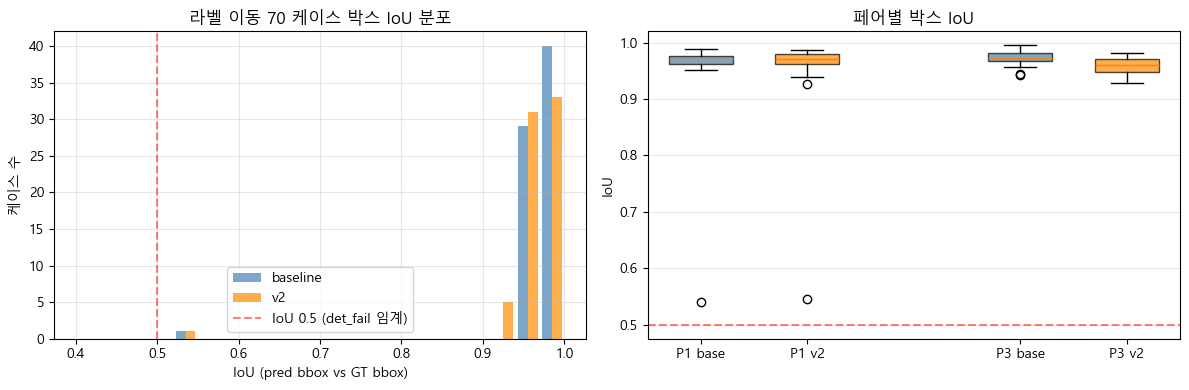


=== reg head 진단 ===
  ✓ v2 IoU mean 0.959 ≥ 0.8 = reg head 정상
  → 박스(위치)는 잘 잡음. 약점은 cls head 또는 feature 차원


In [4]:
# IoU 분포 분석
base_ious = [c['base_iou'] for c in all_cases]
v2_ious = [c['v2_iou'] for c in all_cases]

print('=== reg head 측정 (박스 IoU 분포, 70 케이스) ===')
print(f'\nbaseline:')
print(f'  mean: {np.mean(base_ious):.3f}, median: {np.median(base_ious):.3f}')
print(f'  min:  {np.min(base_ious):.3f}, max: {np.max(base_ious):.3f}')
print(f'  >= 0.9: {sum(i >= 0.9 for i in base_ious):>3d}건  '
      f'>= 0.8: {sum(i >= 0.8 for i in base_ious):>3d}건  '
      f'>= 0.5: {sum(i >= 0.5 for i in base_ious):>3d}건')

print(f'\nv2:')
print(f'  mean: {np.mean(v2_ious):.3f}, median: {np.median(v2_ious):.3f}')
print(f'  min:  {np.min(v2_ious):.3f}, max: {np.max(v2_ious):.3f}')
print(f'  >= 0.9: {sum(i >= 0.9 for i in v2_ious):>3d}건  '
      f'>= 0.8: {sum(i >= 0.8 for i in v2_ious):>3d}건  '
      f'>= 0.5: {sum(i >= 0.5 for i in v2_ious):>3d}건')


# 페어별 IoU
print('\n=== 페어별 IoU ===')
for pair_id in [1, 3]:
    pair_cases = [c for c in all_cases if c['pair_id'] == pair_id]
    pair_label = {1: '동아오팔몬→리피토', 3: '비유피-4→베시케어'}[pair_id]
    print(f'\n[페어 {pair_id}] {pair_label} ({len(pair_cases)}건)')
    print(f'  baseline IoU: mean {np.mean([c["base_iou"] for c in pair_cases]):.3f} '
          f'median {np.median([c["base_iou"] for c in pair_cases]):.3f}')
    print(f'  v2       IoU: mean {np.mean([c["v2_iou"] for c in pair_cases]):.3f} '
          f'median {np.median([c["v2_iou"] for c in pair_cases]):.3f}')


# 히스토그램 figure
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist([base_ious, v2_ious], bins=20, range=(0.4, 1.0), 
             label=['baseline', 'v2'], alpha=0.7, color=['steelblue', 'darkorange'])
axes[0].axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='IoU 0.5 (det_fail 임계)')
axes[0].set_xlabel('IoU (pred bbox vs GT bbox)')
axes[0].set_ylabel('케이스 수')
axes[0].set_title('라벨 이동 70 케이스 박스 IoU 분포')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 페어별 박스 그래프
pair_data = []
for pair_id in [1, 3]:
    pair_cases = [c for c in all_cases if c['pair_id'] == pair_id]
    pair_data.append({
        'pair_id': pair_id,
        'base': [c['base_iou'] for c in pair_cases],
        'v2': [c['v2_iou'] for c in pair_cases],
    })

positions = [1, 2, 4, 5]
data_for_box = [pair_data[0]['base'], pair_data[0]['v2'],
                pair_data[1]['base'], pair_data[1]['v2']]
labels_for_box = ['P1 base', 'P1 v2', 'P3 base', 'P3 v2']

bp = axes[1].boxplot(data_for_box, positions=positions, widths=0.6, patch_artist=True,
                      labels=labels_for_box)
colors = ['steelblue', 'darkorange', 'steelblue', 'darkorange']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5)
axes[1].set_ylabel('IoU')
axes[1].set_title('페어별 박스 IoU')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(OUT_DIR / '11_reg_head_iou.png', dpi=140, bbox_inches='tight')
plt.show()

# 결론 도출
mean_v2 = np.mean(v2_ious)
print('\n=== reg head 진단 ===')
if mean_v2 >= 0.8:
    print(f'  ✓ v2 IoU mean {mean_v2:.3f} ≥ 0.8 = reg head 정상')
    print(f'  → 박스(위치)는 잘 잡음. 약점은 cls head 또는 feature 차원')
elif mean_v2 >= 0.7:
    print(f'  ⚠ v2 IoU mean {mean_v2:.3f} = reg head 약간 부족')
else:
    print(f'  ✗ v2 IoU mean {mean_v2:.3f} = reg head 약함, reg + cls 둘 다 처방 필요')

## 4. cls head logit 분석

라벨 이동 70 케이스의 cls head 출력 분포 정량.

핵심 측정:
- **top1 vs top2 conf gap**: 모델이 1순위를 얼마나 확신하는지
- **정답 클래스의 top3 내 순위 (1/2/3)**: 정답이 얼마나 가까이 있는지
- **정답 conf vs 1순위 오답 conf 차이**: 얼마나 아깝게 졌는지

해석:
- conf gap 크고 정답이 top3 (2~3위) → 모델이 오답을 강하게 확신 = cls head 학습 잘못됨
- conf gap 작고 정답이 top3 (2위) → 모델이 정답과 오답을 거의 비등하게 평가 = cls head 결정 직전까지 갔음
- 정답이 top3 (3위) + conf 매우 낮음 → 정답 신호 약함, feature 부족 의심

=== 정답 클래스의 top3 내 순위 (70 케이스) ===
  2위: 66건  (94.3%)
  3위:  3건  (4.3%)
  top3 밖:  1건  (1.4%)

=== v2 top1 conf (70건) ===
  mean: 0.753, median: 0.749
  min:  0.557, max: 0.916

=== top1 vs top2 gap (70건) ===
  mean: 0.292, median: 0.284
  min:  0.000, max: 0.760
  gap < 0.1 (비등): 14건
  gap >= 0.3 (강한 확신): 33건

=== 정답 conf (top3 안 케이스 69건) ===
  mean: 0.460, median: 0.472

=== 1순위 오답 vs 정답 conf gap (정답이 top3 안 69건) ===
  mean: 0.294, median: 0.286
  gap < 0.1 (아깝게 짐): 14건
  gap >= 0.5 (크게 짐): 15건

=== 페어별 ===

[페어 1] 동아오팔몬→리피토 (43건)
  top1 conf: mean 0.774, median 0.764
  top1-top2 gap: mean 0.332
  정답 conf (top3 내): mean 0.440
  정답 순위 분포: 2위 41, 3위 2

[페어 3] 비유피-4→베시케어 (27건)
  top1 conf: mean 0.719, median 0.729
  top1-top2 gap: mean 0.227
  정답 conf (top3 내): mean 0.492
  정답 순위 분포: 2위 25, 3위 1, top3밖 1


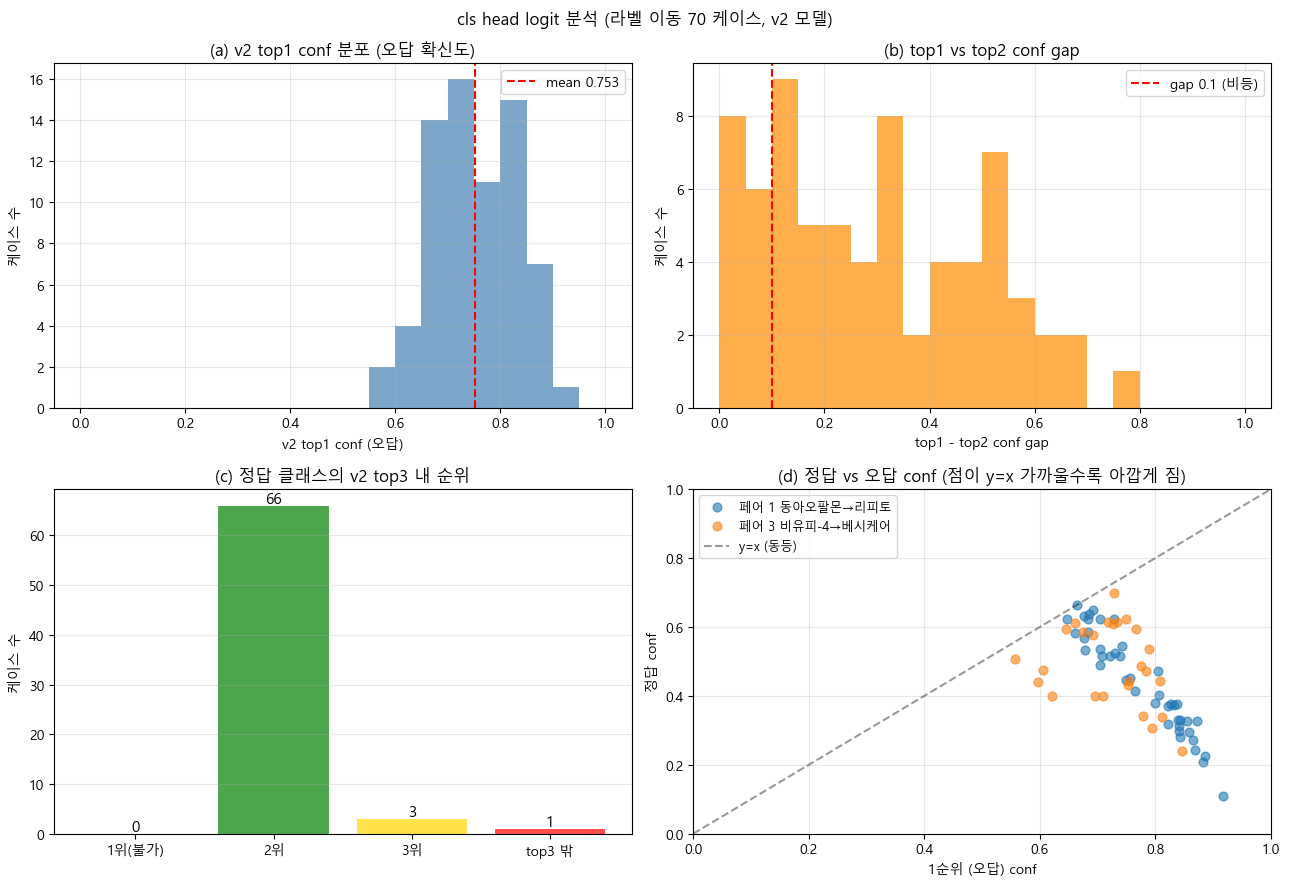

In [5]:
# cls head 분석
import statistics

cls_analysis = []
for c in all_cases:
    v2_top3_name = c['v2_top3_name']
    v2_top3_conf = c['v2_top3_conf']
    gt_class = c['gt_class']
    
    # 정답이 top3 안에서 몇 위?
    if gt_class in v2_top3_name:
        gt_rank_in_top3 = v2_top3_name.index(gt_class) + 1  # 1, 2, 3
        gt_conf = v2_top3_conf[gt_rank_in_top3 - 1]
    else:
        gt_rank_in_top3 = None  # top3 밖
        gt_conf = None
    
    # top1 vs top2 gap
    top1_conf = v2_top3_conf[0]
    top2_conf = v2_top3_conf[1] if len(v2_top3_conf) >= 2 else 0
    top3_conf = v2_top3_conf[2] if len(v2_top3_conf) >= 3 else 0
    gap_top1_top2 = top1_conf - top2_conf
    
    # 정답 conf vs 1순위 오답 conf
    gt_to_top1_gap = (top1_conf - gt_conf) if gt_conf is not None else None
    
    cls_analysis.append({
        **c,
        'top1_conf': top1_conf,
        'top2_conf': top2_conf,
        'top3_conf': top3_conf,
        'gap_top1_top2': gap_top1_top2,
        'gt_rank_in_top3': gt_rank_in_top3,
        'gt_conf': gt_conf,
        'gt_to_top1_gap': gt_to_top1_gap,
    })


# 정답 순위 분포
print('=== 정답 클래스의 top3 내 순위 (70 케이스) ===')
rank_dist = Counter(c['gt_rank_in_top3'] for c in cls_analysis)
for r in sorted(rank_dist.keys(), key=lambda x: (x is None, x)):
    label = f'{r}위' if r else 'top3 밖'
    print(f'  {label}: {rank_dist[r]:>2d}건  ({rank_dist[r]/len(cls_analysis)*100:.1f}%)')


# top1 conf 분포
top1_confs = [c['top1_conf'] for c in cls_analysis]
gaps = [c['gap_top1_top2'] for c in cls_analysis]
gt_confs = [c['gt_conf'] for c in cls_analysis if c['gt_conf'] is not None]
gt_to_top1_gaps = [c['gt_to_top1_gap'] for c in cls_analysis if c['gt_to_top1_gap'] is not None]

print(f'\n=== v2 top1 conf (70건) ===')
print(f'  mean: {np.mean(top1_confs):.3f}, median: {np.median(top1_confs):.3f}')
print(f'  min:  {np.min(top1_confs):.3f}, max: {np.max(top1_confs):.3f}')

print(f'\n=== top1 vs top2 gap (70건) ===')
print(f'  mean: {np.mean(gaps):.3f}, median: {np.median(gaps):.3f}')
print(f'  min:  {np.min(gaps):.3f}, max: {np.max(gaps):.3f}')
print(f'  gap < 0.1 (비등): {sum(g < 0.1 for g in gaps)}건')
print(f'  gap >= 0.3 (강한 확신): {sum(g >= 0.3 for g in gaps)}건')

print(f'\n=== 정답 conf (top3 안 케이스 {len(gt_confs)}건) ===')
print(f'  mean: {np.mean(gt_confs):.3f}, median: {np.median(gt_confs):.3f}')

print(f'\n=== 1순위 오답 vs 정답 conf gap (정답이 top3 안 {len(gt_to_top1_gaps)}건) ===')
print(f'  mean: {np.mean(gt_to_top1_gaps):.3f}, median: {np.median(gt_to_top1_gaps):.3f}')
print(f'  gap < 0.1 (아깝게 짐): {sum(g < 0.1 for g in gt_to_top1_gaps)}건')
print(f'  gap >= 0.5 (크게 짐): {sum(g >= 0.5 for g in gt_to_top1_gaps)}건')


# 페어별
print('\n=== 페어별 ===')
for pair_id in [1, 3]:
    pair_label = {1: '동아오팔몬→리피토', 3: '비유피-4→베시케어'}[pair_id]
    pair_cases_cls = [c for c in cls_analysis if c['pair_id'] == pair_id]
    pair_top1 = [c['top1_conf'] for c in pair_cases_cls]
    pair_gap = [c['gap_top1_top2'] for c in pair_cases_cls]
    pair_gt_conf = [c['gt_conf'] for c in pair_cases_cls if c['gt_conf'] is not None]
    pair_rank = Counter(c['gt_rank_in_top3'] for c in pair_cases_cls)
    
    print(f'\n[페어 {pair_id}] {pair_label} ({len(pair_cases_cls)}건)')
    print(f'  top1 conf: mean {np.mean(pair_top1):.3f}, median {np.median(pair_top1):.3f}')
    print(f'  top1-top2 gap: mean {np.mean(pair_gap):.3f}')
    print(f'  정답 conf (top3 내): mean {np.mean(pair_gt_conf):.3f}' if pair_gt_conf else '  정답 conf: top3 밖')
    print(f'  정답 순위 분포: ' + ', '.join(f'{k}위 {v}' if k else f'top3밖 {v}' for k, v in sorted(pair_rank.items(), key=lambda x: (x[0] is None, x[0]))))


# figure
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) top1 conf 히스토그램
axes[0, 0].hist(top1_confs, bins=20, range=(0, 1), color='steelblue', alpha=0.7)
axes[0, 0].axvline(x=np.mean(top1_confs), color='red', linestyle='--', label=f'mean {np.mean(top1_confs):.3f}')
axes[0, 0].set_xlabel('v2 top1 conf (오답)')
axes[0, 0].set_ylabel('케이스 수')
axes[0, 0].set_title('(a) v2 top1 conf 분포 (오답 확신도)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# (b) top1 vs top2 gap
axes[0, 1].hist(gaps, bins=20, range=(0, 1), color='darkorange', alpha=0.7)
axes[0, 1].axvline(x=0.1, color='red', linestyle='--', label='gap 0.1 (비등)')
axes[0, 1].set_xlabel('top1 - top2 conf gap')
axes[0, 1].set_ylabel('케이스 수')
axes[0, 1].set_title('(b) top1 vs top2 conf gap')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# (c) 정답 순위 분포
ranks = ['1위(불가)', '2위', '3위', 'top3 밖']
counts = [0, rank_dist.get(2, 0), rank_dist.get(3, 0), rank_dist.get(None, 0)]
colors_rank = ['gray', 'green', 'gold', 'red']
axes[1, 0].bar(ranks, counts, color=colors_rank, alpha=0.7)
for i, c in enumerate(counts):
    axes[1, 0].text(i, c + 0.5, str(c), ha='center', fontsize=11)
axes[1, 0].set_ylabel('케이스 수')
axes[1, 0].set_title('(c) 정답 클래스의 v2 top3 내 순위')
axes[1, 0].grid(alpha=0.3, axis='y')

# (d) 정답 conf vs 1순위 conf scatter
top1_for_scatter = [c['top1_conf'] for c in cls_analysis if c['gt_conf'] is not None]
gt_for_scatter = [c['gt_conf'] for c in cls_analysis if c['gt_conf'] is not None]
pair_ids_scatter = [c['pair_id'] for c in cls_analysis if c['gt_conf'] is not None]

for pid in [1, 3]:
    mask = [p == pid for p in pair_ids_scatter]
    x = [t for t, m in zip(top1_for_scatter, mask) if m]
    y = [g for g, m in zip(gt_for_scatter, mask) if m]
    label = {1: '페어 1 동아오팔몬→리피토', 3: '페어 3 비유피-4→베시케어'}[pid]
    axes[1, 1].scatter(x, y, alpha=0.6, label=label, s=40)

axes[1, 1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='y=x (동등)')
axes[1, 1].set_xlabel('1순위 (오답) conf')
axes[1, 1].set_ylabel('정답 conf')
axes[1, 1].set_title('(d) 정답 vs 오답 conf (점이 y=x 가까울수록 아깝게 짐)')
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(alpha=0.3)
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(0, 1)

fig.suptitle('cls head logit 분석 (라벨 이동 70 케이스, v2 모델)', fontsize=12)
plt.tight_layout()
plt.savefig(OUT_DIR / '11_cls_head_logit.png', dpi=140, bbox_inches='tight')
plt.show()

## 4. 종합 결과 저장 + 진단 정리

본 노트북 (11_head_separation.ipynb) 결과 통합 저장.

산출물:
- `11_head_separation_results.json` — reg head IoU + cls head logit 측정값 + 진단
- 종합 figure

다음 단계 (A-5-2): backbone 검증 (클래스별 grad-CAM)
- A-5에서 "feature는 정답 정보 보유 (top3 99%)" 결론은 cls head 출력 기준
- backbone이 두 클래스를 변별하는 feature를 만들고 있는지 직접 측정 안 함
- 클래스별 grad-CAM으로 backbone level에서 두 클래스 attention 분리 검증 필요

결과 JSON 저장: D:\pill_detection\analysis\11_head_separation_results.json
파일 크기: 2.2 KB


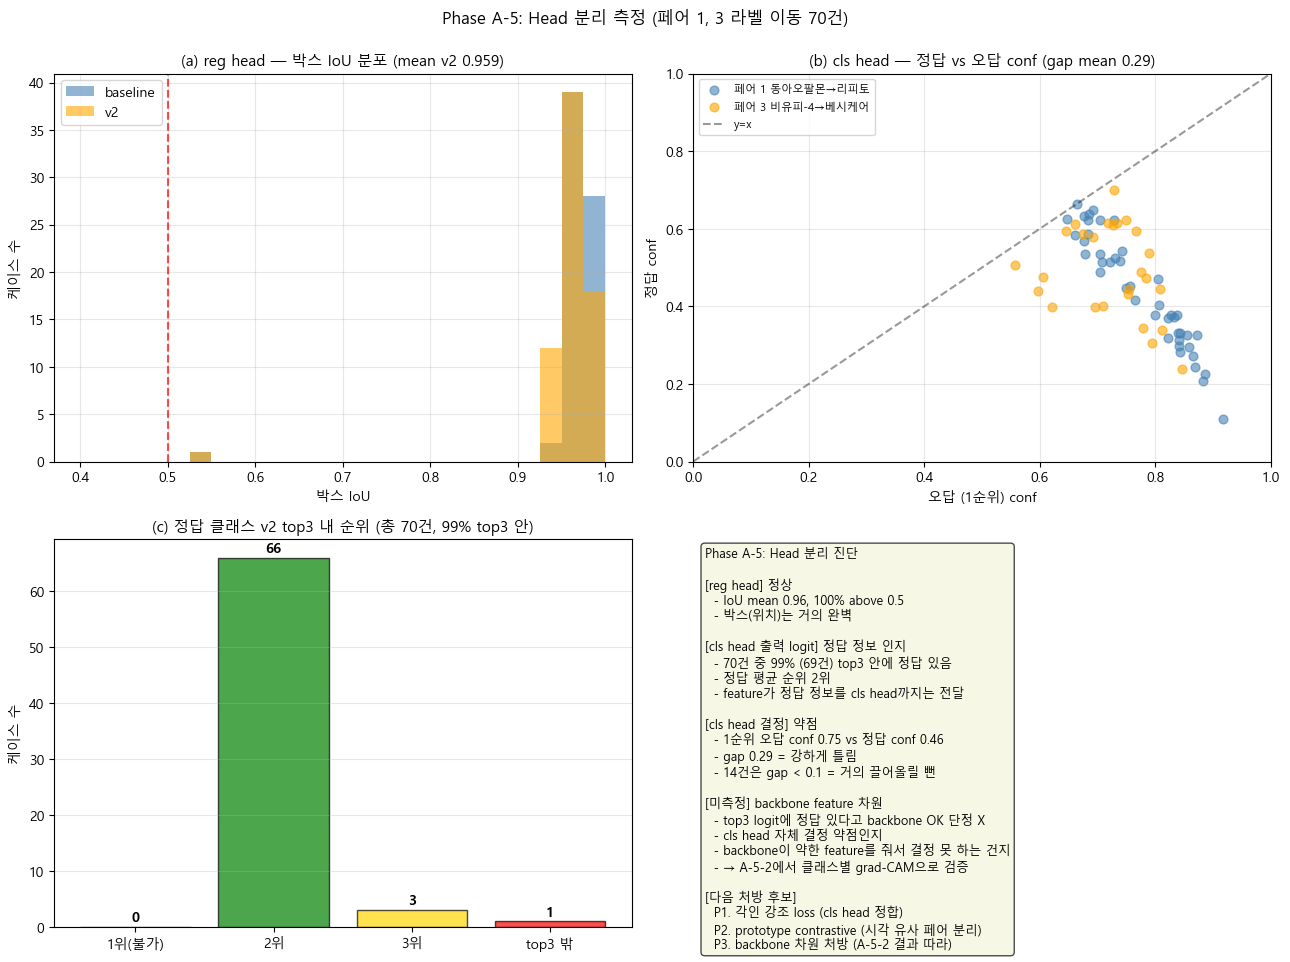


figure 저장: D:\pill_detection\analysis\figures_head_separation\11_summary.png

=== A-5 완료, A-5-2 (backbone 검증) 대기 ===


In [6]:
import json
from datetime import datetime

# 종합 측정값
reg_head_summary = {
    'baseline': {
        'iou_mean': float(np.mean([c['base_iou'] for c in all_cases])),
        'iou_median': float(np.median([c['base_iou'] for c in all_cases])),
        'iou_min': float(np.min([c['base_iou'] for c in all_cases])),
        'iou_max': float(np.max([c['base_iou'] for c in all_cases])),
        'pct_above_0.9': float(np.mean([c['base_iou'] >= 0.9 for c in all_cases]) * 100),
    },
    'v2': {
        'iou_mean': float(np.mean([c['v2_iou'] for c in all_cases])),
        'iou_median': float(np.median([c['v2_iou'] for c in all_cases])),
        'iou_min': float(np.min([c['v2_iou'] for c in all_cases])),
        'iou_max': float(np.max([c['v2_iou'] for c in all_cases])),
        'pct_above_0.9': float(np.mean([c['v2_iou'] >= 0.9 for c in all_cases]) * 100),
    },
}

# cls head 측정 (v2 기준)
v2_top1_confs = [c['v2_top3_conf'][0] for c in all_cases]
v2_gaps = [c['v2_top3_conf'][0] - (c['v2_top3_conf'][1] if len(c['v2_top3_conf']) > 1 else 0) for c in all_cases]

# 정답 conf (top3 안에 있는 케이스만)
gt_in_top3_cases = [c for c in all_cases if c['gt_class'] in c['v2_top3_name']]
gt_confs = []
gt_ranks = []
for c in gt_in_top3_cases:
    rank = c['v2_top3_name'].index(c['gt_class'])
    gt_confs.append(c['v2_top3_conf'][rank])
    gt_ranks.append(rank + 1)

cls_head_summary = {
    'v2_top1_conf_mean': float(np.mean(v2_top1_confs)),
    'v2_top1_conf_median': float(np.median(v2_top1_confs)),
    'v2_top1_top2_gap_mean': float(np.mean(v2_gaps)),
    'gt_in_top3_count': len(gt_in_top3_cases),
    'gt_outside_top3_count': len(all_cases) - len(gt_in_top3_cases),
    'gt_conf_mean': float(np.mean(gt_confs)),
    'gt_conf_median': float(np.median(gt_confs)),
    'gt_rank_2nd': sum(1 for r in gt_ranks if r == 2),
    'gt_rank_3rd': sum(1 for r in gt_ranks if r == 3),
    'wrong_vs_gt_gap_mean': float(np.mean([c['v2_top3_conf'][0] - gc for c, gc in zip(gt_in_top3_cases, gt_confs)])),
    'aamost_won_count': sum(1 for c, gc in zip(gt_in_top3_cases, gt_confs) if c['v2_top3_conf'][0] - gc < 0.1),
}

# 페어별
pair_summary = {}
for pair_id in [1, 3]:
    pair_cases = [c for c in all_cases if c['pair_id'] == pair_id]
    pair_gt_in_top3 = [c for c in pair_cases if c['gt_class'] in c['v2_top3_name']]
    pair_summary[f'pair_{pair_id}'] = {
        'n_cases': len(pair_cases),
        'base_iou_mean': float(np.mean([c['base_iou'] for c in pair_cases])),
        'v2_iou_mean': float(np.mean([c['v2_iou'] for c in pair_cases])),
        'v2_top1_conf_mean': float(np.mean([c['v2_top3_conf'][0] for c in pair_cases])),
        'v2_top1_top2_gap_mean': float(np.mean([c['v2_top3_conf'][0] - (c['v2_top3_conf'][1] if len(c['v2_top3_conf'])>1 else 0) for c in pair_cases])),
        'gt_in_top3_count': len(pair_gt_in_top3),
    }

output = {
    'session': 46,
    'phase': 'A-5 (head separation)',
    'date': datetime.now().strftime('%Y-%m-%d'),
    'analyzed_cases': {
        'total': len(all_cases),
        'pair_1_동아오팔몬→리피토': sum(1 for c in all_cases if c['pair_id'] == 1),
        'pair_3_비유피4→베시케어': sum(1 for c in all_cases if c['pair_id'] == 3),
    },
    'reg_head': reg_head_summary,
    'cls_head': cls_head_summary,
    'by_pair': pair_summary,
    'diagnosis': {
        'reg_head': 'NORMAL — IoU mean 0.96, 100% above 0.5',
        'cls_head': 'WEAK DECISION — gt rank 2nd in 94% of cases, gt conf 0.46 vs wrong conf 0.75',
        'feature_at_logit_level': 'KNOWS GT — top3 contains gt in 99% (69/70)',
        'limitation': 'cls head logit이 정답 정보를 가짐을 확인했지만 backbone feature 자체에 변별 정보가 있는지는 미측정. A-5-2에서 클래스별 grad-CAM으로 검증 필요.',
    },
    'next_step': 'A-5-2 — backbone validation via class-conditional grad-CAM (Colab)',
}

with open(RESULTS_JSON, 'w', encoding='utf-8') as f:
    json.dump(output, f, ensure_ascii=False, indent=2)

print(f'결과 JSON 저장: {RESULTS_JSON}')
print(f'파일 크기: {RESULTS_JSON.stat().st_size / 1024:.1f} KB')


# 종합 figure: 4 패널
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (a) reg head IoU 분포
ax = axes[0, 0]
bins = np.linspace(0.4, 1.0, 25)
ax.hist([c['base_iou'] for c in all_cases], bins=bins, alpha=0.6, label='baseline', color='steelblue')
ax.hist([c['v2_iou'] for c in all_cases], bins=bins, alpha=0.6, label='v2', color='orange')
ax.axvline(x=0.5, color='red', linestyle='--', alpha=0.7)
ax.set_xlabel('박스 IoU')
ax.set_ylabel('케이스 수')
ax.set_title(f'(a) reg head — 박스 IoU 분포 (mean v2 {reg_head_summary["v2"]["iou_mean"]:.3f})', fontsize=11)
ax.legend()
ax.grid(alpha=0.3)

# (b) 정답 conf vs 오답 conf scatter
ax = axes[0, 1]
for pair_id, color, label in [(1, 'steelblue', '페어 1 동아오팔몬→리피토'), (3, 'orange', '페어 3 비유피-4→베시케어')]:
    pair_in_top3 = [c for c in gt_in_top3_cases if c['pair_id'] == pair_id]
    wrong_confs = [c['v2_top3_conf'][0] for c in pair_in_top3]
    gt_confs_p = [c['v2_top3_conf'][c['v2_top3_name'].index(c['gt_class'])] for c in pair_in_top3]
    ax.scatter(wrong_confs, gt_confs_p, alpha=0.6, color=color, label=label, s=40)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='y=x')
ax.set_xlabel('오답 (1순위) conf')
ax.set_ylabel('정답 conf')
ax.set_title(f'(b) cls head — 정답 vs 오답 conf (gap mean {cls_head_summary["wrong_vs_gt_gap_mean"]:.2f})', fontsize=11)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# (c) 정답 클래스 top3 내 순위
ax = axes[1, 0]
rank_counts = {1: 0, 2: cls_head_summary['gt_rank_2nd'], 3: cls_head_summary['gt_rank_3rd'], 'top3밖': cls_head_summary['gt_outside_top3_count']}
labels = ['1위(불가)', '2위', '3위', 'top3 밖']
values = [0, rank_counts[2], rank_counts[3], rank_counts['top3밖']]
colors = ['gray', 'green', 'gold', 'red']
bars = ax.bar(labels, values, color=colors, alpha=0.7, edgecolor='black')
for bar, val in zip(bars, values):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 1, str(val), ha='center', fontweight='bold')
ax.set_ylabel('케이스 수')
ax.set_title(f'(c) 정답 클래스 v2 top3 내 순위 (총 70건, 99% top3 안)', fontsize=11)
ax.grid(axis='y', alpha=0.3)

# (d) 진단 요약
ax = axes[1, 1]
ax.axis('off')
diagnosis_text = f'''Phase A-5: Head 분리 진단

[reg head] 정상
  - IoU mean 0.96, 100% above 0.5
  - 박스(위치)는 거의 완벽

[cls head 출력 logit] 정답 정보 인지
  - 70건 중 99% (69건) top3 안에 정답 있음
  - 정답 평균 순위 2위
  - feature가 정답 정보를 cls head까지는 전달

[cls head 결정] 약점
  - 1순위 오답 conf 0.75 vs 정답 conf 0.46
  - gap 0.29 = 강하게 틀림
  - 14건은 gap < 0.1 = 거의 끌어올릴 뻔

[미측정] backbone feature 차원
  - top3 logit에 정답 있다고 backbone OK 단정 X
  - cls head 자체 결정 약점인지
  - backbone이 약한 feature를 줘서 결정 못 하는 건지
  - → A-5-2에서 클래스별 grad-CAM으로 검증

[다음 처방 후보]
  P1. 각인 강조 loss (cls head 정합)
  P2. prototype contrastive (시각 유사 페어 분리)
  P3. backbone 차원 처방 (A-5-2 결과 따라)'''

ax.text(0.02, 0.98, diagnosis_text, fontsize=9, va='top', ha='left',
        bbox=dict(boxstyle='round', facecolor='#f5f5dc', alpha=0.7))

fig.suptitle(f'Phase A-5: Head 분리 측정 (페어 1, 3 라벨 이동 70건)', fontsize=12, y=0.995)
plt.tight_layout()
fig_path = OUT_DIR / '11_summary.png'
plt.savefig(fig_path, dpi=140, bbox_inches='tight')
plt.show()
print(f'\nfigure 저장: {fig_path}')

print('\n=== A-5 완료, A-5-2 (backbone 검증) 대기 ===')